In [1]:
COLAB = False
SWIFT = False
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "last_expr_or_assign"

%matplotlib widget

from IPython.display import HTML, display

# standard imports
import numpy as np
from scipy import linalg
import matplotlib.pyplot as plt
import math
from math import pi
np.set_printoptions(
    linewidth=120, formatter={
        'float': lambda x: f"{0:8.4g}" if abs(x) < 1e-10 else f"{x:8.4g}"})
np.random.seed(0)
from spatialmath import *
from spatialmath.base import *

## Exercise 1

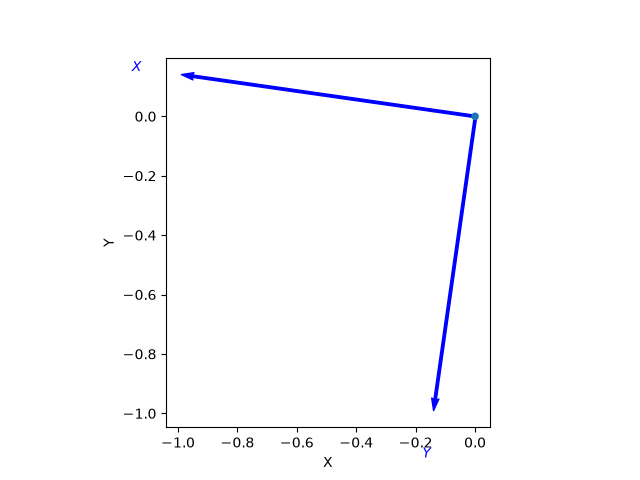

In [ ]:
R = SE2(3.0)
plotvol2(new=True)
trplot2(R.A);

In [14]:
R

  -0.99     -0.1411    0         
   0.1411   -0.99      0         
   0         0         1         


In [16]:
R * [-1, 1]

array([[  0.8489],
       [  -1.131]])

In [19]:
Rinv = R.inv()

  -0.99      0.1411    0         
  -0.1411   -0.99      0         
   0         0         1         


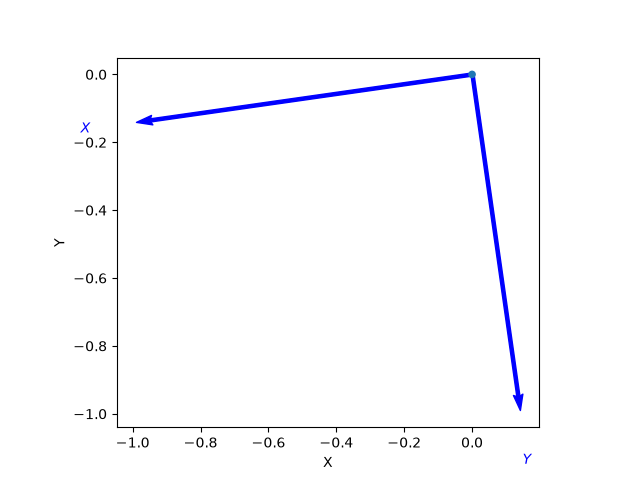

In [24]:
plotvol2(new=True)
trplot2(Rinv.A);

In [17]:
R @ Rinv

   1         0         0         
   0         1         0         
   0         0         1         


In [18]:
Rinv @ R

   1         0         0         
   0         1         0         
   0         0         1         


In [22]:
print(np.linalg.det(R))
print(np.linalg.det(Rinv))
R.det()

0.9999999999999999
0.9999999999999999


np.float64(0.9999999999999999)

## Exercise 3

In [28]:
R = SO3(roty(0.3) @ rotx(0.3))

   0.9553    0.08733   0.2823    
   0         0.9553   -0.2955    
  -0.2955    0.2823    0.9127    


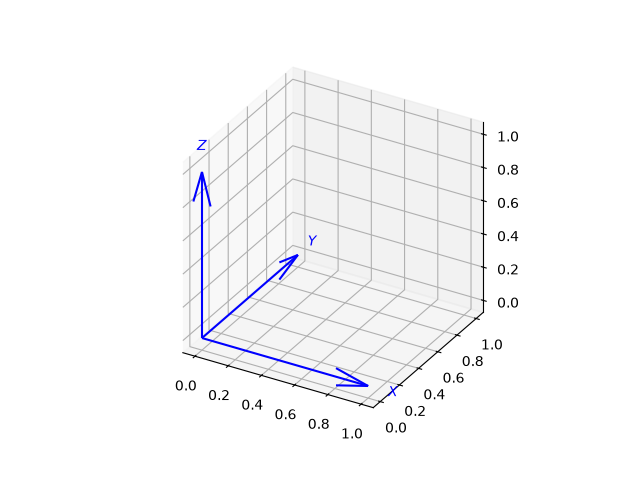

In [30]:
plotvol3(new=True)
tranimate(R);

## Exercise 5

Done by AI.

<Axes3D: xlabel='x', ylabel='y', zlabel='z'>

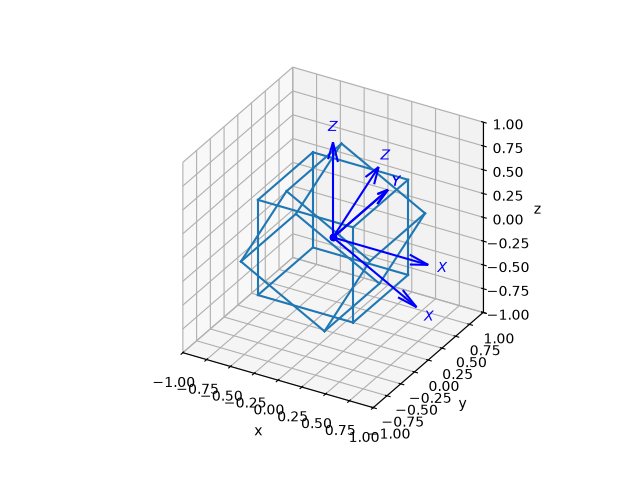

In [ ]:
# A unit cube centered at the origin and its 12 edges.
cube_vertices = np.array([
    [x, y, z]
    for x in (-0.5, 0.5)
    for y in (-0.5, 0.5)
    for z in (-0.5, 0.5)
])
cube_edges = [
    (i, j)
    for i in range(len(cube_vertices))
    for j in range(i + 1, len(cube_vertices))
    if np.count_nonzero(cube_vertices[i] != cube_vertices[j]) == 1
]


def _transformed_cube_vertices(T):
    if hasattr(T, "A"):
        T = T.A
    T = np.asarray(T, dtype=float)
    if T.shape != (4, 4):
        raise ValueError("T must be a 4x4 homogeneous transformation")
    if not np.allclose(T[3], [0, 0, 0, 1]):
        raise ValueError("T must have homogeneous bottom row [0, 0, 0, 1]")
    vertices_h = np.column_stack((cube_vertices, np.ones(len(cube_vertices))))
    return (T @ vertices_h.T).T[:, :3]


def plot_cube(T=np.eye(4)):
    """Plot the transformed cube edges and coordinate frame."""
    vertices = _transformed_cube_vertices(T)
    trplot(T.A if hasattr(T, "A") else T)
    ax = plt.gca()
    for i, j in cube_edges:
        ax.plot(vertices[[i, j], 0], vertices[[i, j], 1], vertices[[i, j], 2],
                color="tab:blue")
    ax.set(xlim=(-1, 1), ylim=(-1, 1), zlim=(-1, 1),
           xlabel="x", ylabel="y", zlabel="z")
    ax.set_box_aspect((1, 1, 1))
    return ax

plotvol3(new=True)
# (a) Plot the cube, then use plot_cube(T) to apply a homogeneous transform.
plot_cube()

# (b) Apply a homogeneous transform to the cube vertices before plotting.
plot_cube(SE3.Rt(roty(0.5), [0, 0, 0]))

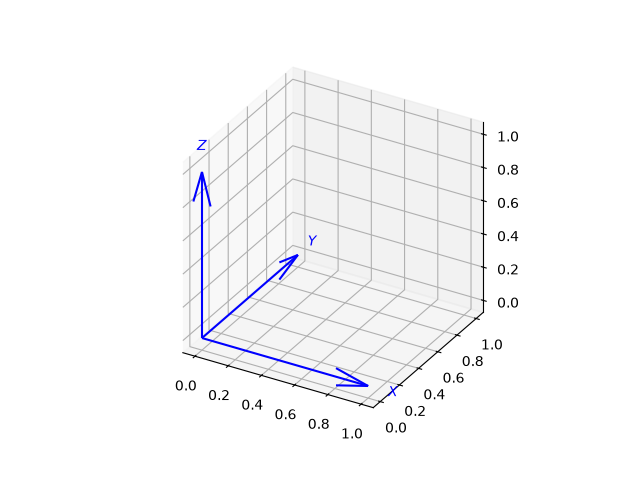

In [ ]:
angles = np.linspace(0, 2 * pi, 120)

# (c) Rotation about the x-axis.
# plt.figure()
plotvol3(new=True)
tranimate(SO3.Rx(angles));

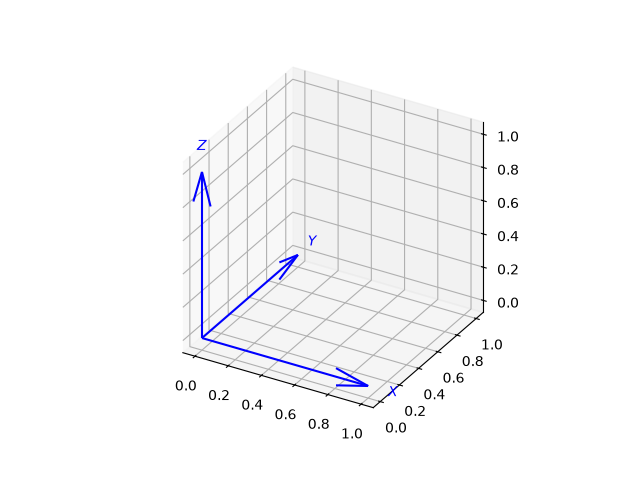

In [19]:
# (d) Simultaneous rotation about all three axes.
plotvol3(new=True)
all_axes = SO3([rotx(a) @ roty(a) @ rotz(a) for a in angles])
tranimate(all_axes);

## Exercise 6

In [ ]:
# this was not the exercise...
class Quat():
    def __init__(self, s, v):
        self.s = s
        self.v = v
        self.vx = self.v[0]
        self.vy = self.v[1]
        self.vz = self.v[2]

    def __repr__(self):
        return f"{self.s} <{self.vx}, {self.vy}, {self.vz}>"

    def __add__(self, other):
        return Quat(
            self.s + other.s,
            (self.vx + other.vx,
            self.vy + other.vy,
            self.vz + other.vz,)
        )

    def __rmul__(self, other):
        return Quat(
            self.s * other,
            (self.vx * other,
            self.vy * other,
            self.vz * other,)
        )

    def __mul__(self, other):
        if isinstance(other, Quat):
            return Quat(
                self.s * other.s - (self.vx * other.vx + self.vy * other.vy + self.vz * other.vz),
                (
                self.s * other.vx + self.vx * other.s + self.vy * other.vz - self.vz * other.vy,
                self.s * other.vy - self.vx * other.vz + self.vy * other.s + self.vz * other.vx,
                self.s * other.vz + self.vx * other.vy - self.vy * other.vx + self.vz * other.s,
                )
            )
        else:
            pass # matrix-vec

    def inv(self):
        denom = self.s**2 + self.vx**2 + self.vy**2 + self.vz**2 
        return (1/denom) * Quat(self.s, (-self.vx, -self.vy, -self.vz))

testq = Quat(1,(1,1,1))
print(testq)
print(testq * testq)
print(testq.inv())
print(testq.inv() * testq)

1 <1, 1, 1>
-2 <2, 2, 2>
0.25 <-0.25, -0.25, -0.25>
1.0 <0.0, 0.0, 0.0>


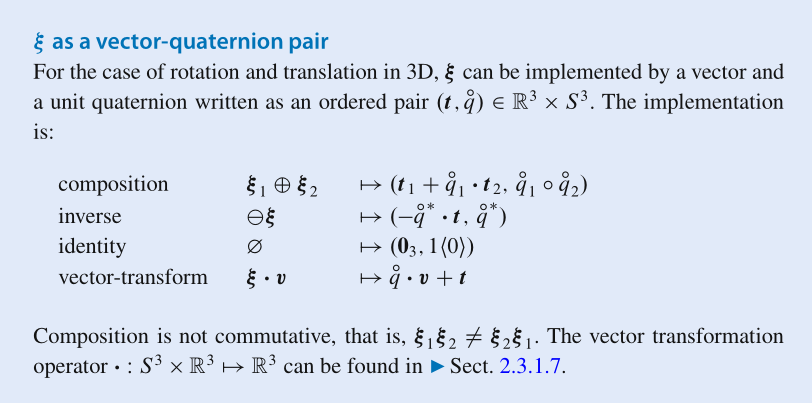

In [ ]:
# the actual exercise, lazy to allow passing tuples
class VectorQuaternion():
    def __init__(self, tx, ty, tz, s, vx, vy, vz):
        self.t = np.array([tx, ty, tz])
        self.q = UnitQuaternion(s=s, v=(vx, vy, vz))

    def __repr__(self):
        return f"VectorQuaternion(t={self.t}, q={self.q})"

    def __mul__(self, other):
        if isinstance(other, VectorQuaternion):
            translation = self.t + self.q * other.t
            q = self.q * other.q
            return VectorQuaternion(
                translation[0], translation[1], translation[2],
                q.s, q.v[0], q.v[1], q.v[2]
            )
        else:
            transformed = self.q * other
            translation = self.t
            if transformed.ndim == 2:
                translation = self.t[:, np.newaxis]
            return transformed + translation

    def inv(self):
        q = self.q.inv()
        translation = -(q * self.t)
        return VectorQuaternion(
            translation[0], translation[1], translation[2],
            q.s, q.v[0], q.v[1], q.v[2]
        )

q1 = UnitQuaternion.Rz(pi / 2)
transform1 = VectorQuaternion(1, 2, 3, q1.s, *q1.v)
q2 = UnitQuaternion.Rx(pi / 2)
transform2 = VectorQuaternion(-1, 0, 2, q2.s, *q2.v)

point = np.array([1, 0, 0])
print("First transform:", transform1)
print("Second transform:", transform2)
print("Transformed point:", transform1 * point)
composed = transform1 * transform2
print("Composed transform:", composed)
inverse = transform1.inv()
print("Inverse transform:", inverse)
print("Applying the inverse to the transformed point:", inverse * (transform1 * point))

First transform: VectorQuaternion(t=[1 2 3], q= 0.7071 <<  0.0000,  0.0000,  0.7071 >>)
Second transform: VectorQuaternion(t=[-1  0  2], q= 0.7071 <<  0.7071,  0.0000,  0.0000 >>)
Transformed point: [       1        3        3]
Composed transform: VectorQuaternion(t=[       1        1        5], q= 0.5000 <<  0.5000,  0.5000,  0.5000 >>)
Inverse transform: VectorQuaternion(t=[      -2        1       -3], q= 0.7071 << -0.0000, -0.0000, -0.7071 >>)
Applying the inverse to the transformed point: [       1        0        0]


## Exercise 7

In [38]:
T = transl(2, 3, 4) @ trotx(0.3)
exact = linalg.expm(T)

series = np.eye(4)
term = np.eye(4)
for i in range(1, 9):
    term = term @ T / i
    series += term

print("Exact:\n", exact)
print(f"Power series ({i+1} terms):\n", series)

Exact:
 [[   2.718        0        0    5.437]
 [       0    2.487  -0.7571    6.313]
 [       0   0.7571    2.487    11.64]
 [       0        0        0    2.718]]
Power series (9 terms):
 [[   2.718        0        0    5.437]
 [       0    2.487  -0.7571    6.313]
 [       0   0.7571    2.487    11.64]
 [       0        0        0    2.718]]


## Exercise 10

In [ ]:
vec = SO3.AngleAxis(0.5, [2,3,4])
magnitude = (2**2+3**2+4**2)**0.5
unit = np.array([2,3,4])/magnitude
print(vec)
print(linalg.expm(0.5*skew(unit)))
print(trexp(unit, 0.5))
print(rodrigues(unit, 0.5))
print(angvec2tr(0.5, [2,3,4])[:3, :3])

SO3_matrix = trexp(unit, 0.5)
unit_q = UnitQuaternion(SO3_matrix)

   0.8945   -0.3308    0.3009    
   0.3814    0.9156   -0.1274    
  -0.2333    0.2287    0.9451    

[[  0.8945  -0.3308   0.3009]
 [  0.3814   0.9156  -0.1274]
 [ -0.2333   0.2287   0.9451]]
[[  0.8945  -0.3308   0.3009]
 [  0.3814   0.9156  -0.1274]
 [ -0.2333   0.2287   0.9451]]
[[  0.8945  -0.3308   0.3009]
 [  0.3814   0.9156  -0.1274]
 [ -0.2333   0.2287   0.9451]]
[[  0.8945  -0.3308   0.3009]
 [  0.3814   0.9156  -0.1274]
 [ -0.2333   0.2287   0.9451]]
 0.9689 <<  0.0919,  0.1378,  0.1838 >>


# Exercise 13

In [16]:
import sympy
r, p, y = sympy.symbols('r p y')
m = rpy2r(r, p, y)
sympy.trigsimp(m)

[[cos(p)*cos(y), sin(p)*sin(r)*cos(y) - sin(y)*cos(r), sin(p)*cos(r)*cos(y) + sin(r)*sin(y)], [sin(y)*cos(p), sin(p)*sin(r)*sin(y) + cos(r)*cos(y), sin(p)*sin(y)*cos(r) - sin(r)*cos(y)], [-sin(p), sin(r)*cos(p), cos(p)*cos(r)]]

In [8]:
unit_z = [0,0,1]
m @ unit_z

array([sin(p)*cos(r)*cos(y) + sin(r)*sin(y), sin(p)*sin(y)*cos(r) - sin(r)*cos(y), cos(p)*cos(r)], dtype=object)

In [ ]:
# finding roll, pitch, yaw from rotation matrix
def m2rpy(m):
    m_p = sympy.asin(-m[2, 0])

    print(sympy.trigsimp(m_p))
m2rpy(m)

asin(sin(p))


# Exercise 15

$$TT^{-1}=
\begin{pmatrix}
RR^{\top} & {}^At_B + R\,{}^Bt_A\\
0_{1\times 3} & 1
\end{pmatrix}
=
\begin{pmatrix}
1_{3\times 3} & {}^At_B - RR^\top{}^At_B\\
0_{1\times 3} & 1
\end{pmatrix}
= I
$$

# Exercise 16

No, for a homogeneous transformation matrix $T$, the inverse is not equal to the transpose. $T^\top$ does not have zeros along the bottom row in general.

# Exercise 18

$$
e^X e^Y = (I + X + \frac{X^2}{2!} + \cdots)(I + Y + \frac{Y^2}{2!} + \cdots)
= I + X + Y + \frac{X^2}{2!} + \frac{Y^2}{2!} + XY + \cdots,
$$

whereas

$$
e^{X+Y} = I + (X + Y) + \frac{(X+Y)^2}{2!} + \cdots
= I + X + Y + \frac{X^2 + XY + YX + Y^2}{2!} + \cdots.
$$

The quadratic terms differ whenever $XY \neq YX$, so $e^X e^Y \neq e^{X+Y}$ in general.

# Exercise 20

A camera with z-axis parallel to $[0, 1, 0]$ and y-axis parallel to $[0, 0, -1]$ has x-axis

$$
x = y \times z =
\begin{bmatrix}0\\0\\-1\end{bmatrix} \times \begin{bmatrix}0\\1\\0\end{bmatrix}
= \begin{bmatrix}1\\0\\0\end{bmatrix}.
$$

So the camera attitude relative to the world frame is

$$
R = \begin{bmatrix}
1 & 0 & 0\\
0 & 0 & 1\\
0 & -1 & 0
\end{bmatrix}.
$$

This is a rotation of $-\pi/2$ about the world x-axis. The corresponding unit quaternion is

$$
q = \cos(-\pi/2) \langle \sin(-\pi/2), 0, 0\rangle
$$


In [22]:
R = SO3(np.array([
    [1, 0, 0],
    [0, 0, 1],
    [0, -1, 0]
]))
UnitQuaternion(R)

 0.7071 << -0.7071,  0.0000,  0.0000 >>


Above illustrates that for a unit quaternion $\mathring q = -\mathring q$. 